In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
dataset_path = "realwaste"

print("Dataset path:", dataset_path)

Dataset path: realwaste


In [3]:
categories = os.listdir(dataset_path)

print("Waste Categories:")
for category in categories:
    print(category)

Waste Categories:
Cardboard
Food Organics
Glass
Metal
Miscellaneous Trash
Paper
Plastic
Textile Trash
Vegetation


In [4]:
for category in categories:
    category_path = os.path.join(dataset_path, category)
    image_count = len(os.listdir(category_path))
    print(f"{category}: {image_count} images")

Cardboard: 461 images
Food Organics: 411 images
Glass: 420 images
Metal: 790 images
Miscellaneous Trash: 495 images
Paper: 500 images
Plastic: 921 images
Textile Trash: 318 images
Vegetation: 436 images


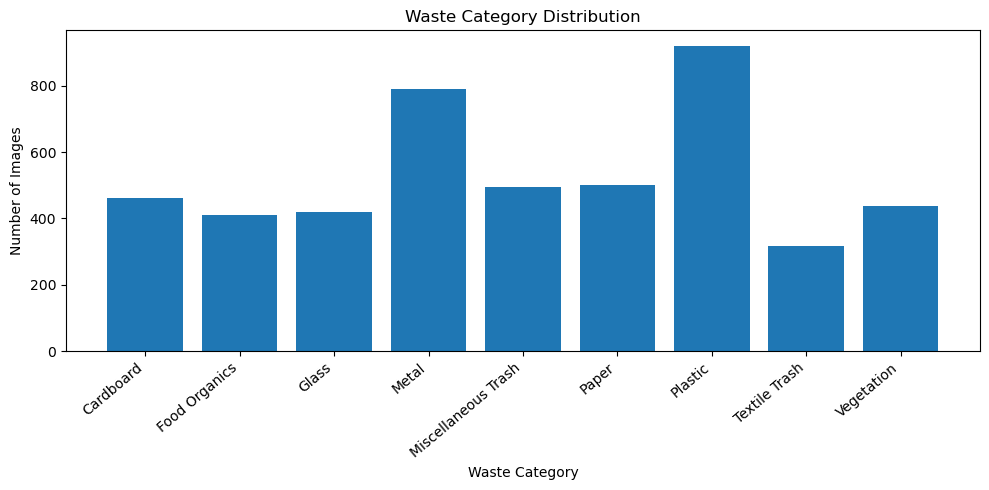

In [5]:
image_counts = []

for category in categories:
    category_path = os.path.join(dataset_path, category)
    image_count = len(os.listdir(category_path))
    image_counts.append(image_count)

plt.figure(figsize=(10, 5))
plt.bar(categories, image_counts)
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.title("Waste Category Distribution")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

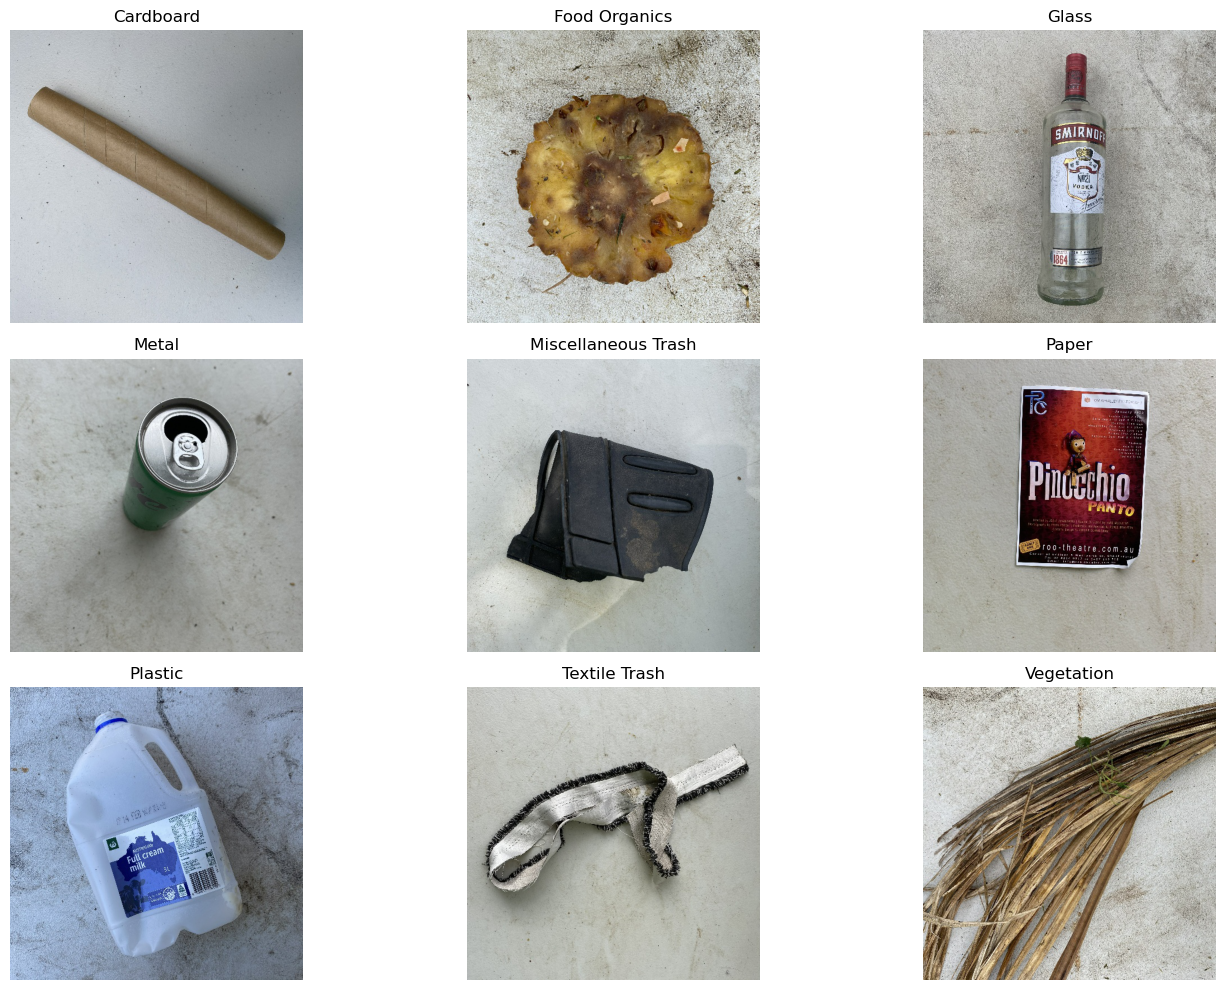

In [6]:
plt.figure(figsize=(15, 10))

for i, category in enumerate(categories):
    category_path = os.path.join(dataset_path, category)
    image_name = os.listdir(category_path)[0]
    image_path = os.path.join(category_path, image_name)

    image = Image.open(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(category)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
for category in categories:
    category_path = os.path.join(dataset_path, category)
    image_name = os.listdir(category_path)[0]
    image_path = os.path.join(category_path, image_name)

    image = Image.open(image_path)

    print(f"{category}: {image.size}")

Cardboard: (524, 524)
Food Organics: (524, 524)
Glass: (524, 524)
Metal: (524, 524)
Miscellaneous Trash: (524, 524)
Paper: (524, 524)
Plastic: (524, 524)
Textile Trash: (524, 524)
Vegetation: (524, 524)


In [8]:
for category in categories:
    category_path = os.path.join(dataset_path, category)
    image_name = os.listdir(category_path)[0]
    image_path = os.path.join(category_path, image_name)

    image = Image.open(image_path)

    print(f"{category}: {image.mode}")

Cardboard: RGB
Food Organics: RGB
Glass: RGB
Metal: RGB
Miscellaneous Trash: RGB
Paper: RGB
Plastic: RGB
Textile Trash: RGB
Vegetation: RGB


In [9]:
IMG_SIZE = 128

image = Image.open(image_path)
image = image.resize((IMG_SIZE, IMG_SIZE))

image_array = np.array(image)
image_array = image_array / 255.0

print("New shape:", image_array.shape)
print("Pixel range:", image_array.min(), "to", image_array.max())

New shape: (128, 128, 3)
Pixel range: 0.0 to 0.9137254901960784


In [30]:
X = []
y = []

for category in categories:
    category_path = os.path.join(dataset_path, category)

    for image_name in os.listdir(category_path):
        image_path = os.path.join(category_path, image_name)

        try:
            image = Image.open(image_path).convert("RGB")
            image = image.resize((IMG_SIZE, IMG_SIZE))

            image_array = np.array(image) / 255.0

            X.append(image_array)
            y.append(category)

        except:
            pass

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4752, 128, 128, 3)
y shape: (4752,)


In [34]:
for category, number in zip(label_encoder.classes_,
                            label_encoder.transform(label_encoder.classes_)):
    print(category, "→", number)

Cardboard → 0
Food Organics → 1
Glass → 2
Metal → 3
Miscellaneous Trash → 4
Paper → 5
Plastic → 6
Textile Trash → 7
Vegetation → 8


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3801, 128, 128, 3)
Testing data: (951, 128, 128, 3)


In [38]:
unique_classes, class_counts = np.unique(y_train, return_counts=True)

for class_id, count in zip(unique_classes, class_counts):
    print(label_encoder.inverse_transform([class_id])[0], "→", count)

Cardboard → 369
Food Organics → 329
Glass → 336
Metal → 632
Miscellaneous Trash → 396
Paper → 400
Plastic → 736
Textile Trash → 254
Vegetation → 349


In [48]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [42]:
print(tf.__version__)

2.18.0


In [46]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(9, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 9)                   │           1,161 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,801 (12.61 MB)

 Trainable params: 3,305,801 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [52]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 45s 428ms/step - accuracy: 0.1828 - loss: 2.1759 - val_accuracy: 0.3679 - val_loss: 1.8340
Epoch 2/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 36s 378ms/step - accuracy: 0.3187 - loss: 1.8460 - val_accuracy: 0.3693 - val_loss: 1.7369
Epoch 3/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 36s 378ms/step - accuracy: 0.3896 - loss: 1.6910 - val_accuracy: 0.4376 - val_loss: 1.5367
Epoch 4/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 37s 387ms/step - accuracy: 0.4451 - loss: 1.5591 - val_accuracy: 0.4704 - val_loss: 1.4567
Epoch 5/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 36s 379ms/step - accuracy: 0.4699 - loss: 1.4263 - val_accuracy: 0.5085 - val_loss: 1.3550
Epoch 6/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 38s 401ms/step - accuracy: 0.5165 - loss: 1.3302 - val_accuracy: 0.5007 - val_loss: 1.3745
Epoch 7/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 37s 391ms/step - accuracy: 0.5327 - loss: 1.2870 - val_accuracy: 0.5112 - val_loss: 1.3561
Epoch 8/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 37s 388ms/step - accuracy: 0.5422 - loss: 1.2224 - val_accu

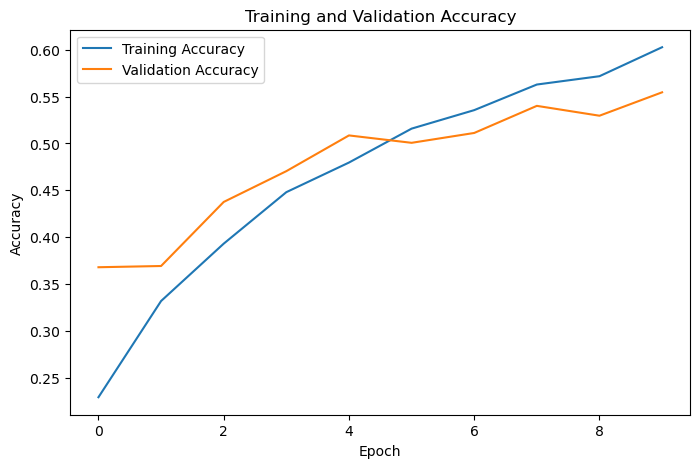

In [76]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.savefig("training_validation_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

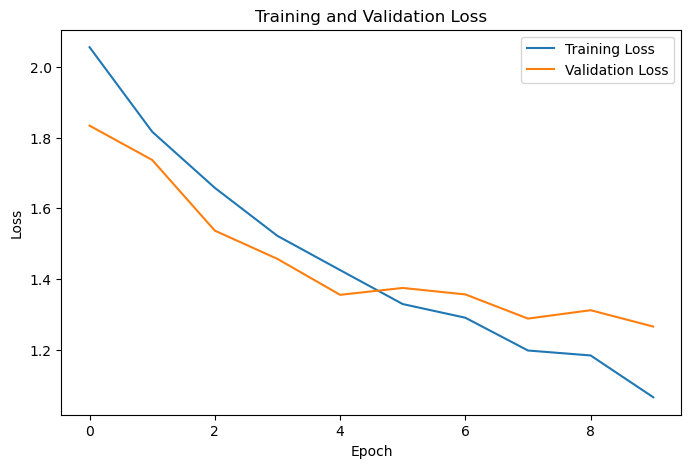

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.savefig("training_validation_loss.png", dpi=300, bbox_inches="tight")
plt.show()

In [58]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.5911 - loss: 1.1754
Test Accuracy: 0.6035751700401306
Test Loss: 1.1600092649459839


In [60]:
# Generate predictions for test data

y_pred = model.predict(X_test)

# Convert probabilities to class labels
y_pred_classes = np.argmax(y_pred, axis=1)

print("Predictions generated!")

30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step
Predictions generated!


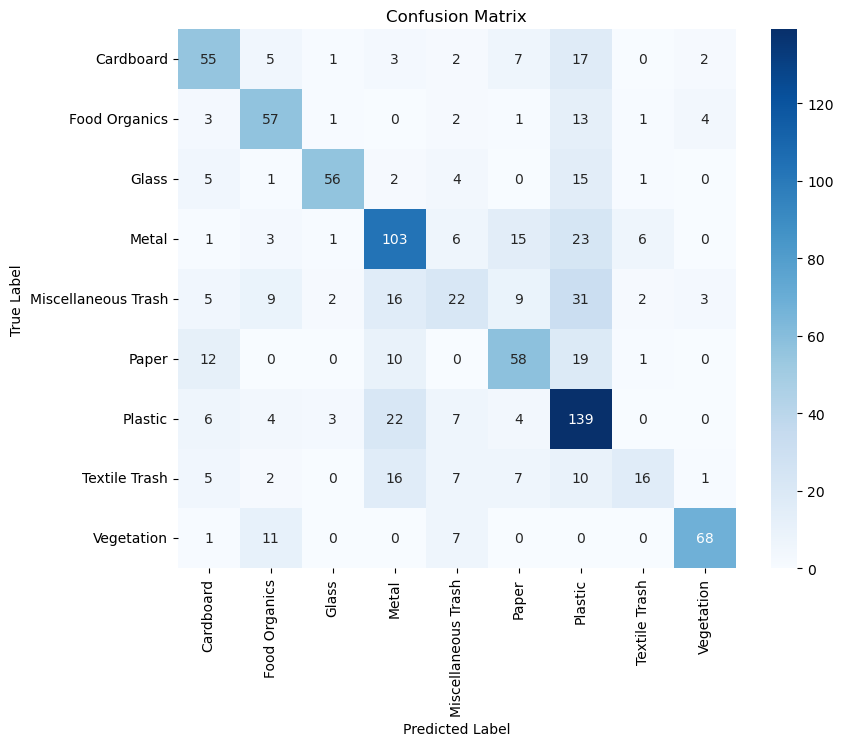

In [80]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [64]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_classes,
    target_names=label_encoder.classes_
))

                     precision    recall  f1-score   support

          Cardboard       0.59      0.60      0.59        92
      Food Organics       0.62      0.70      0.66        82
              Glass       0.88      0.67      0.76        84
              Metal       0.60      0.65      0.62       158
Miscellaneous Trash       0.39      0.22      0.28        99
              Paper       0.57      0.58      0.58       100
            Plastic       0.52      0.75      0.62       185
      Textile Trash       0.59      0.25      0.35        64
         Vegetation       0.87      0.78      0.82        87

           accuracy                           0.60       951
          macro avg       0.63      0.58      0.59       951
       weighted avg       0.61      0.60      0.59       951



In [68]:
model.save("Trash_classification_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [70]:
sample_index = 0

sample_image = X_test[sample_index]
actual_label = label_encoder.inverse_transform([y_test[sample_index]])[0]

print("Actual Class:", actual_label)

Actual Class: Metal


In [72]:
sample_prediction = model.predict(
    np.expand_dims(sample_image, axis=0)
)

predicted_class = np.argmax(sample_prediction)

predicted_label = label_encoder.inverse_transform(
    [predicted_class]
)[0]

confidence = np.max(sample_prediction) * 100

print("Actual Class:", actual_label)
print("Predicted Class:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
Actual Class: Metal
Predicted Class: Metal
Confidence: 96.87 %


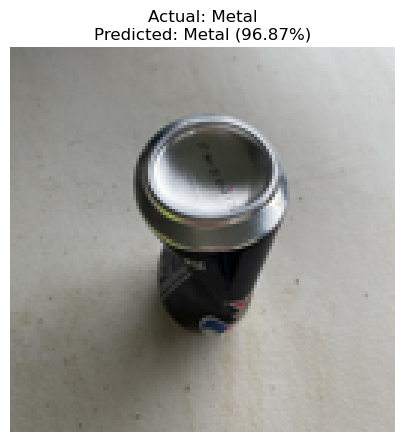

In [82]:
plt.figure(figsize=(5, 5))

plt.imshow(sample_image)
plt.title(
    f"Actual: {actual_label}\n"
    f"Predicted: {predicted_label} ({confidence:.2f}%)"
)

plt.axis("off")
plt.savefig("sample_prediction.png", dpi=300, bbox_inches="tight")
plt.show()